In [1]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord, EarthLocation, AltAz, concatenate
from astropy.coordinates.erfa_astrom import erfa_astrom, ErfaAstromInterpolator
from astropy.time import Time
from astropy.table import QTable

from ctapipe.io import TableLoader
from ctapipe.coordinates import TelescopeFrame
from ctapipe.core import QualityQuery
from ctapipe.io import HDF5MonitoringSource, TelescopeMonitoringType
from ctapipe.image.hillas import camera_to_shower_coordinates

In [2]:
erfa_astrom.set(ErfaAstromInterpolator(10 * u.min))

<ScienceState erfa_astrom: <astropy.coordinates.erfa_astrom.ErfaAstromInterpolator object at 0x7f1d4a1c27b0>>

In [3]:
files = {"on": "build/on.dl1.h5", "off": "build/off.dl1.h5"}

datasets = {}


for name, path in files.items():
    with TableLoader(path) as loader:
        subarray = loader.subarray

        dataset = {}
        events = QTable(loader.read_telescope_events(pointing=True), copy=False)
        
        dataset["events"] = events
        dataset["obs"] = loader.read_observation_information()
        dataset["obs"]["scheduled_start_time"].format = "isot"

        ontime_events = events[events['hillas_intensity'] > 250]
        t = ontime_events["time"]
        dataset["ontime"] = len(ontime_events) * np.mean((t[1:] - t[:-1]).to(u.s))
        events["rate_weight"] = 1 / dataset["ontime"].to_value(u.s)
        datasets[name] = dataset

In [4]:
for name, dataset in datasets.items():
    print(name, len(dataset["events"]), "Events", f", ontime: {dataset["ontime"].to(u.min):.1f}")
    
    print(dataset["obs"][["obs_id", "scheduled_start_time"]])
    print()

on 101775 Events , ontime: 135.0 min
obs_id   scheduled_start_time 
------ -----------------------
  5106 1996-05-07T03:35:57.795
  5108 1996-05-07T04:19:24.590
  5109 1996-05-07T04:48:03.780
  5110 1996-05-07T05:16:49.200
  5111 1996-05-07T05:45:24.380

off 9427 Events , ontime: 11.3 min
obs_id   scheduled_start_time 
------ -----------------------
  5107 1996-05-07T04:05:52.880



In [5]:
# add pointing from individual runs..., maybe merging wasn't so convenient in the end

for name, dataset in datasets.items():
    events = dataset["events"]
    for col in ("altitude", "azimuth"):
        events[f"telescope_pointing_{col}"] = u.Quantity(np.zeros(len(events)), u.deg, copy=False)
    
    for obs_id in dataset["obs"]["obs_id"]:
        source = HDF5MonitoringSource(input_files=[f"./build/{name}/gt{obs_id:06d}.pointing.mon.h5"], timestamp_tolerance="60 s")
    
        mask = events["obs_id"] == obs_id
        pointing = source.get_telescope_values(1, events[mask]["time"], TelescopeMonitoringType.TELESCOPE_POINTINGS)
        
        events["telescope_pointing_altitude"][mask] = pointing.alt.to(u.deg)
        events["telescope_pointing_azimuth"][mask] = pointing.az.to(u.deg)
    
    events["pointing"] = SkyCoord(
        alt=events["telescope_pointing_altitude"],
        az=events["telescope_pointing_azimuth"],
        frame=AltAz(obstime=events["time"], location=subarray.reference_location)
    )

[Text(0, 0.5, 'Pointing Altitude / deg')]

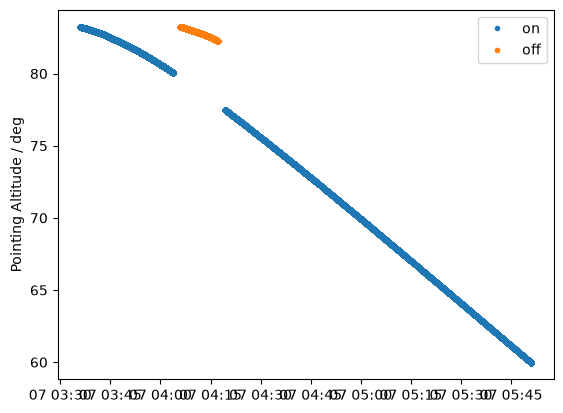

In [6]:
fig, ax = plt.subplots()

for name, dataset in datasets.items():
    events = dataset["events"]
    ax.plot(events["time"].to_datetime(), events["pointing"].alt.deg, '.', label=name)

ax.legend()
ax.set(ylabel='Pointing Altitude / deg')

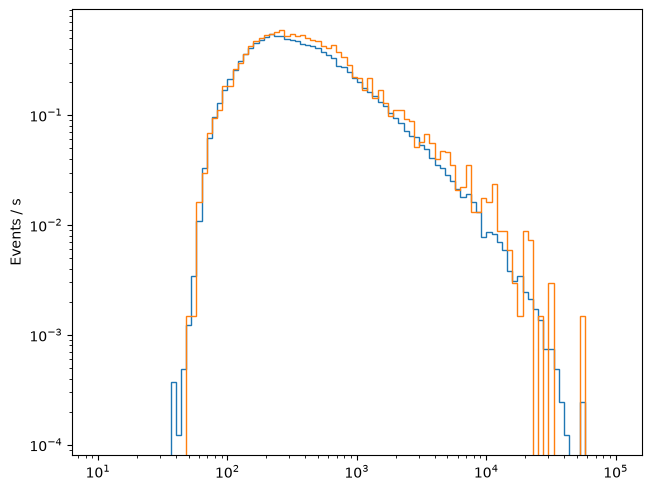

In [7]:
fig, ax = plt.subplots(1, 1, layout="constrained")

for name, dataset in datasets.items():
    events = dataset["events"]
    
    ax.hist(
        events["hillas_intensity"],
        bins=np.geomspace(10, 1e5, 101),
        label="name",
        histtype="step",
        weights=events["rate_weight"],
    )

ax.set(xscale="log", yscale="log", ylabel='Events / s')
None

In [8]:
mrk421 = SkyCoord.from_name("Mrk 421")

In [9]:
mrk421_tel_frame = mrk421.transform_to(
    TelescopeFrame(
        telescope_pointing=events["pointing"],
        location=subarray.reference_location,
        obstime=events["time"],
    )
)

In [10]:
# should be close to 0, on obs
mrk421_tel_frame.fov_lon.mean(), mrk421_tel_frame.fov_lon.std()

(<Longitude -5.21329354 deg>, <Longitude 0.24102094 deg>)

In [11]:
for dataset in datasets.values():
    events = dataset["events"]
    
    # assume source in camera center, works for on/ off
    long, trans = camera_to_shower_coordinates(
        0 * u.deg,
        0 * u.deg,
        events["hillas_fov_lon"],
        events["hillas_fov_lat"],
        events["hillas_psi"],
    )
    
    alpha = np.abs(np.arctan(trans / long).to(u.deg))
    events["alpha"] = alpha

In [12]:
# some cuts, from Karl Kosack here: https://github.com/kosack/wuparam/blob/master/support/SuperCuts2001.conf
query = QualityQuery(
    quality_criteria=[
        ("width_low", "hillas_width >= 0.05 * u.deg"),
        ("width_high", "hillas_width <= 0.12 * u.deg"),
        ("length_low", "hillas_length >= 0.13 * u.deg"),
        ("length_high", "hillas_length <= 0.25 * u.deg"),
        ("distance_low", "hillas_r >= 0.4 * u.deg"),
        ("distance_high", "hillas_r <= 1.0 * u.deg"),
    ],
)

In [13]:
for name, dataset in datasets.items():
    events = dataset["events"]
    events["mask"] = query.get_table_mask(events)
    dataset["selected"] = events[events["mask"]]

    print(name, len(events), len(dataset["selected"]), len(dataset["selected"]) / len(events))

on 101775 3387 0.033279292557111276
off 9427 219 0.02323114458470351


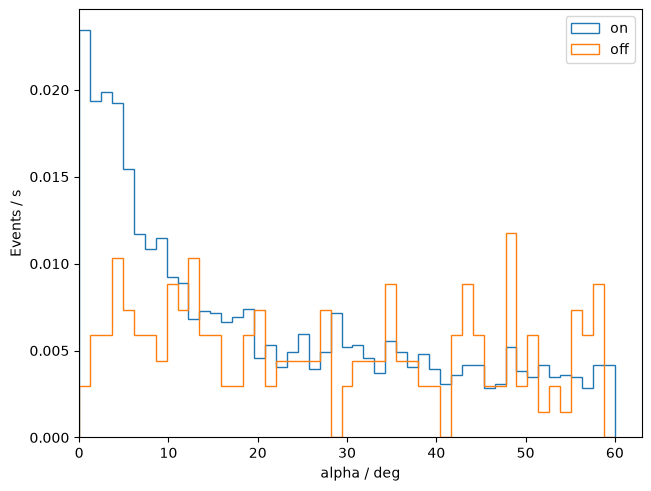

In [14]:
fig, ax = plt.subplots(1, 1, layout="constrained")

for name, dataset in datasets.items():
    selected = dataset["selected"]
    
    ax.hist(
        selected["alpha"].to_value(u.deg),
        bins=np.linspace(0, 60, 50),
        weights=selected["rate_weight"],
        histtype='step',
        label=name,
    )

ax.set(xlabel="alpha / deg", xlim=(0, None), ylabel='Events / s')
ax.legend()
None